# What iBART can (and can't) find

iBART discovers **nonlinear equations**. It builds nonlinear descriptors by
composing operators (`square, sqrt, log, exp, sin, cos, abs, *, /, |a-b|`) on
the inputs. The final model is *linear in the coefficients on a nonlinear basis*
(like SINDy or polynomial regression): the discovered equation is nonlinear, but
the fit is convex.

This notebook shows what it recovers, its one real limitation, and two
workarounds.

## 1. Nonlinear expressions it recovers exactly

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jax_ibart import IBart

rng = np.random.default_rng(0)
n = 200
x1, x2, x3 = (rng.uniform(0.1, 1, n) for _ in range(3))
X = np.column_stack([x1, x2, x3]); names = ["x1", "x2", "x3"]

def fit_and_score(y, schedule):
    m = IBart(backend="diff", schedule=schedule, max_dim=1, seed=0, steps=1500).fit(X, y, names)
    pred = m.predict(X)
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return m, pred, r2

cases = [
    ("sin(pi*x1*x2)", np.sin(np.pi * x1 * x2), ("b", "u")),
    ("(exp(x1)-exp(x2))^2", (np.exp(x1) - np.exp(x2)) ** 2, ("u", "b", "u")),
]
results = []
for label, y, sched in cases:
    m, pred, r2 = fit_and_score(y, sched)
    results.append((label, y, pred, m, r2))
    print(f"{label:>22}  ->  {m.descriptors_}   R2={r2:.4f}")

         sin(pi*x1*x2)  ->  [sin(pi*x1*x2)]   R2=1.0000


   (exp(x1)-exp(x2))^2  ->  [Abs(exp(x1) - exp(x2))**2]   R2=1.0000


Parity plots: the recovered nonlinear models land on the diagonal.

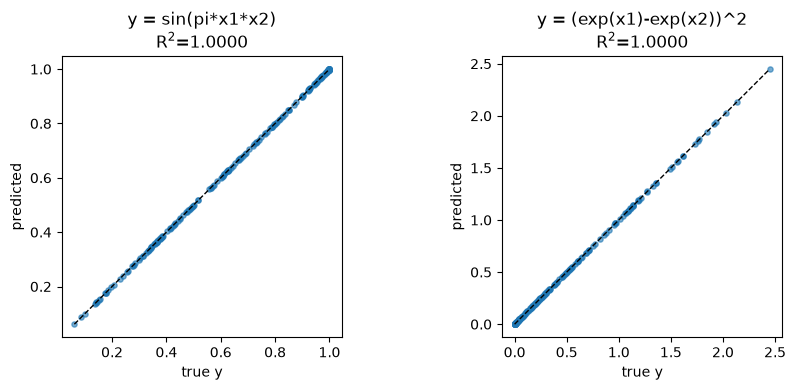

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (label, y, pred, m, r2) in zip(axes, results):
    ax.scatter(y, pred, s=14, alpha=0.6)
    lo, hi = float(y.min()), float(y.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_title(f"y = {label}\nR$^2$={r2:.4f}")
    ax.set_xlabel("true y"); ax.set_ylabel("predicted"); ax.set_aspect("equal")
fig.tight_layout(); plt.show()

Both are recovered exactly (R^2 = 1.0). Transcendental, rational, product and
composed nonlinearities are all in scope, as long as the operators can build them.

## 2. The one real limitation: free parameters *inside* a nonlinearity

iBART fits **linear coefficients** on an operator-generated library. It cannot
fit a *continuous parameter inside* a term unless that exact term is generated.
A power law with a non-integer exponent is the classic case: there is no
arbitrary-power operator, so `x^2.3` can only be *approximated* (here by `x^2`).

In [3]:
xp = rng.uniform(0.5, 3.0, n)
Xp = np.column_stack([xp, rng.uniform(0, 1, n)])
y = xp ** 2.3                      # exponent 2.3 is not constructible
m = IBart(backend="diff", schedule=("u",), max_dim=1, seed=0, steps=1200).fit(Xp, y, ["x", "d"])
pr = m.predict(Xp)
print("x^2.3  -> found", m.descriptors_,
      f" R2={1 - ((y-pr)**2).sum()/((y-y.mean())**2).sum():.4f}  (approximate, not exact)")

x^2.3  -> found [x**2]  R2=0.9979  (approximate, not exact)


Plotting the fit against `x` shows the approximation drifting from the true curve:

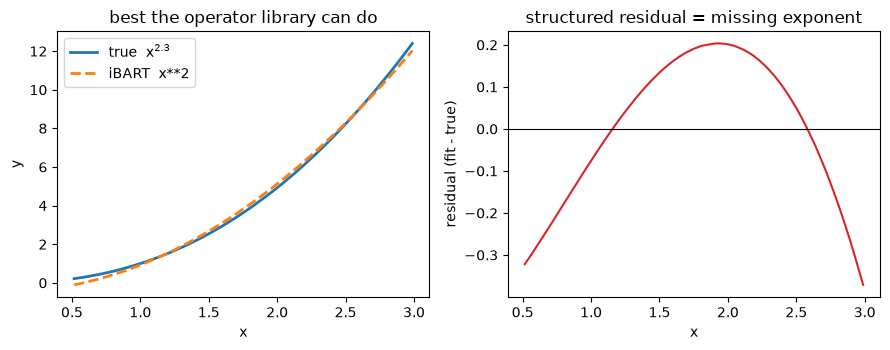

In [4]:
order = np.argsort(xp)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(xp[order], y[order], lw=2, label="true  x$^{2.3}$")
axes[0].plot(xp[order], pr[order], "--", lw=2, label=f"iBART  {m.descriptors_[0]}")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y"); axes[0].legend()
axes[0].set_title("best the operator library can do")
axes[1].plot(xp[order], (pr - y)[order], color="C3")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("x"); axes[1].set_ylabel("residual (fit - true)")
axes[1].set_title("structured residual = missing exponent")
fig.tight_layout(); plt.show()

The same goes for **Arrhenius** `k = A exp(-E/RT)`, with a fitted activation
energy `E` inside the exponential, and **Michaelis-Menten** `v = Vmax S/(Km+S)`,
with a fitted `Km` in the denominator. Both are nonlinear *in the parameters*.
There are two standard fixes.

### Workaround A: linearize (Arrhenius)

Taking logs gives `ln k = ln A - (E/R)(1/T)`, which is linear in the descriptor
`1/T`. So we give iBART `ln k` as the target, add the `inv` operator (it is not
in the default unary set), and include two irrelevant features to make it a real
search.

In [5]:
from jax_ibart.operators import UNARY, default_unary

R = 8.314
T = rng.uniform(300, 600, n)          # K
P = rng.uniform(1, 10, n)             # irrelevant
xA = rng.uniform(0, 1, n)             # irrelevant
k = 1e3 * np.exp(-50000 / (R * T)) * np.exp(rng.normal(0, 0.02, n))   # 2% noise

arr = IBart(backend="diff", schedule=("u",), max_dim=1, seed=0, steps=1500,
            unary_ops=default_unary() + [UNARY["inv"]])
arr.fit(np.column_stack([T, P, xA]), np.log(k), ["T", "P", "x_A"])
print("descriptor:", arr.descriptors_)
E_hat, A_hat = -arr.coef_[1] * R, np.exp(arr.coef_[0])
print(f"recovered E = {E_hat:,.0f} J/mol   (true 50,000)")
print(f"recovered A = {A_hat:,.0f}          (true 1,000)")

descriptor: [1/T]
recovered E = 49,959 J/mol   (true 50,000)
recovered A = 987          (true 1,000)


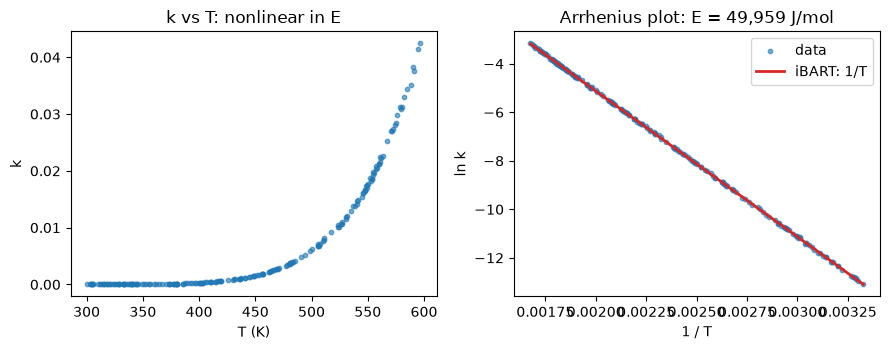

In [6]:
o = np.argsort(T)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(T, k, s=10, alpha=0.6)
axes[0].set_xlabel("T (K)"); axes[0].set_ylabel("k")
axes[0].set_title("k vs T: nonlinear in E")
axes[1].scatter(1 / T, np.log(k), s=10, alpha=0.6, label="data")
axes[1].plot(1 / T[o], arr.coef_[0] + arr.coef_[1] / T[o], "C3", lw=2,
             label=f"iBART: {arr.descriptors_[0]}")
axes[1].set_xlabel("1 / T"); axes[1].set_ylabel("ln k")
axes[1].set_title(f"Arrhenius plot: E = {E_hat:,.0f} J/mol")
axes[1].legend()
fig.tight_layout(); plt.show()

### Workaround B: implicit, null-space form (Michaelis-Menten)

**What "null space" means.** Usual regression fits `y = f(x)`: one column is the
target and we predict it from the others. A constraint like `x^2 + y^2 = 1` has
no target. Instead, some weighted sum of candidate terms is **always zero**.

So build a table whose columns are candidate terms (here `S, v, S^2, v^2, S*v`
and a column of ones). We want weights `w` such that

    w1*S + w2*v + ... + w6*1  =  0   for every row.

That weight vector is a **null-space vector** of the table: multiplying the table
by it gives all zeros. Ordinary regression cannot find it, because there is no
`y`. A singular value decomposition (SVD) can: the direction along which the data
never vary is exactly the constraint. The smallest singular value measures how
close to zero it is (0 means an exact law).

For Michaelis-Menten, rearranging `v = Vmax*S/(Km+S)` gives
`Vmax*S - Km*v - S*v = 0`, a sum of terms that is always zero. That is what we
recover:

In [7]:
from jax_ibart.dynamics import implicit_constraints
import sympy as sp

Vmax, Km = 5.0, 2.0
S = rng.uniform(0.1, 10.0, n)
v = Vmax * S / (Km + S)

# v(Km + S) = Vmax S  ->  Vmax*S - Km*v - S*v = 0  : an algebraic constraint
res = implicit_constraints(np.column_stack([S, v]), ["S", "v"], degree=2, tol=1e-2)
print("recovered constraint:", sp.nsimplify(res["constraint"], rational=False).evalf(3))
print("residual (0 = exact):", round(res["residual"], 6))
print("\ntrue: 5*S - 2*v - S*v = 0  ->  divide by 5:  S - 0.4*v - 0.2*S*v = 0")

recovered constraint: 0.2*S*v - S + 0.4*v
residual (0 = exact): 0.0

true: 5*S - 2*v - S*v = 0  ->  divide by 5:  S - 0.4*v - 0.2*S*v = 0


Reconstructing `v(S)` from the recovered coefficients reproduces the data:

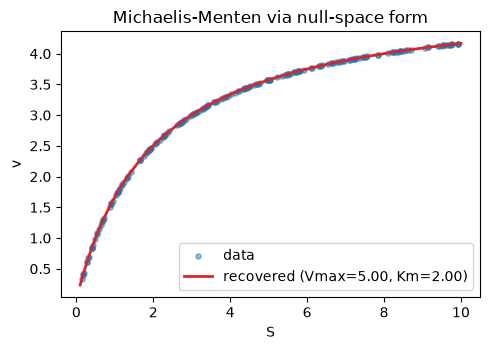

In [8]:
# constraint:  cS*S + cv*v + cSv*S*v + ... = 0  ->  solve for v(S)
# coef vector aligns with res['terms']; pull the S, v, S*v weights
terms = res["terms"]; w = res["coef"]
def wof(name): return w[terms.index(name)]
cS, cv, cSv = wof("S"), wof("v"), wof("S*v")
# cS*S + cv*v + cSv*S*v = 0  ->  v = -cS*S / (cv + cSv*S)
Sg = np.linspace(0.1, 10, 100)
v_fit = -cS * Sg / (cv + cSv * Sg)
Vmax_hat, Km_hat = -cS / cSv, cv / cSv

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.scatter(S, v, s=14, alpha=0.5, label="data")
ax.plot(Sg, v_fit, "C3", lw=2, label=f"recovered (Vmax={Vmax_hat:.2f}, Km={Km_hat:.2f})")
ax.set_xlabel("S"); ax.set_ylabel("v"); ax.set_title("Michaelis-Menten via null-space form")
ax.legend(); fig.tight_layout(); plt.show()

The implicit (null-space) formulation recovers the Michaelis-Menten law
**exactly** as an algebraic constraint, and `Vmax` and `Km` can be read off the
coefficients (here Vmax = 5, Km = 2). This is the same machinery that underlies
the DAE foundation (`implicit_constraints`) and SINDy-PI (see
[references](../references.md)).

**Summary:** nonlinear *expressions* are what iBART is for. Free parameters
*inside* a nonlinearity need an operator that builds the term, a linearizing
transform, or the implicit null-space form.